# Experiment 6 — XGBoost as a Diversity Arm

**Starting point:** experiment-5.1 best config = LightGBM-MAE + multi-seed averaging
→ **CV-WAPE 14.73** / leaderboard WAPE 14.93. The rejected ideas from exp-5 (bias
correction, 4-way multi-objective ensemble) failed because the four LightGBM-based
arms (MAE / Poisson / Tweedie / Ridge) all had highly correlated residuals — the
ensemble had no real diversity to exploit.

**Hypothesis:** XGBoost trained with `reg:absoluteerror` (MAE) on the same features
produces residuals that are **decorrelated from LightGBM's** — because XGBoost grows
trees **depth-wise** while LightGBM grows them **leaf-wise**. Each algorithm prefers
different splits and learns different functions of the same features. A 2-way blend
of the two MAE-objective models is the smallest, most principled diversity ensemble
this pipeline can try.

**Plan:**

| § | Step | Why | Expected ΔWAPE |
|---|------|-----|---------------:|
| §4 | Reproduce LGBM-MAE baseline | sanity check pipeline matches exp-5.1 | — (= 14.78) |
| §5 | XGBoost-MAE solo | establish XGB's standalone CV-WAPE on the same features | unclear |
| §6 | Small XGB grid sanity | confirm baseline XGB params aren't badly off | −0 to −0.1 |
| §7 | **LGBM-MAE + XGB-MAE 2-way blend** | core hypothesis — diversity ensemble | −0.1 to −0.3 |
| §8 | + Poisson + Tweedie + Ridge (5-way) | does XGB rescue the 4-way blend exp-5 rejected? | −0 to −0.2 |
| §9 | Multi-seed averaging on winner | proven helper (exp-5.1 gain ≈ 0.05) | −0.05 |
| §10 | Refit + submit | — | — |

**Discipline (same as exp-5):**

1. All config in §0 — one place to edit.
2. Each section: markdown rationale → code → markdown decision.
3. Every improvement has an explicit accept rule (e.g. "Δ > 0.05 WAPE"); rejections
   are recorded and skipped at submission time.
4. The submission writer in §10 reads only the final flags; analysis sections never
   write to `OUTPUT_DIR`.

**What this notebook does NOT change vs exp-5:**

- Feature pipeline (52 features, same lag/lead/rolling temporal context)
- CV folds (3-fold rolling-origin, 336h test per fold)
- Per-fold `series_mean` recomputation (leakage-free)
- `sid_code` categorical handling (XGBoost gets it via `enable_categorical=True`)

**What this notebook does change vs exp-5:**

- Imputation: now `ffill().bfill()` within series, sorted by timestamp
  (was `ffill().fillna(0)`). Justified by `data-analysis-2.ipynb` §2-5.
  Confirmed harmless in exp-5.1 (+0.004 WAPE on the leaderboard, well within noise).
- Adds XGBoost-MAE as a candidate model and blend arm.
- Skips bias correction (rejected in exp-5; nothing about XGBoost changes that
  conclusion — it would still find the conditional median).

---
## §0. Configuration

Everything that you might want to tweak lives in this one cell.

In [1]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
# Kaggle (default):
DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
OUTPUT_DIR   = Path("/kaggle/working")
# Local fallback:
if not DATA_DIR.exists():
    DATA_DIR   = Path("data")
    OUTPUT_DIR = Path("experiment-6")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED         = 42
N_FOLDS      = 3
EVAL_HORIZON = 336      # 14-day forecast window (hours)

# ── Feature config (identical to exp-5) ──────────────────────────────────────
DOMAIN_FEAT_COLS = [
    "workload_intensity", "demand_forecast", "upstream_quality_forecast",
    "promotion_intensity", "shock_risk", "maintenance_known",
    "unit_reliability_forecast", "queue_pressure_forecast",
    "network_pressure_forecast", "event_load_forecast",
    "service_irregularity_risk_forecast",
]
TIME_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
             "doy_sin", "doy_cos", "is_weekend"]
TOP_DOM    = ["queue_pressure_forecast", "network_pressure_forecast",
              "workload_intensity", "shock_risk", "event_load_forecast"]
TOP3_ROLL  = TOP_DOM[:3]
LAGS_DOM   = [1, 24]
LEADS_DOM  = [1, 24]
ROLL_WINS  = [6, 24]

# ── LightGBM baseline (matches exp-5.1's STEP1_PARAMS) ──────────────────────
BASELINE_LGBM = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
    reg_lambda=1.0, verbose=-1,
)

# ── XGBoost baseline ─────────────────────────────────────────────────────────
# Parameter mapping LGBM → XGBoost:
#   num_leaves=63   → max_depth=6     (2^6 = 64 leaves, similar capacity)
#   min_child_samples=50 → min_child_weight=50  (sum of Hessian, similar reg effect)
#   subsample / colsample_bytree / reg_lambda are the same names in both libs
BASELINE_XGB = dict(
    objective="reg:absoluteerror",   # MAE — same loss as LGBM-MAE
    tree_method="hist",              # required for enable_categorical
    enable_categorical=True,         # sid_code is passed as pandas categorical
    n_estimators=600, learning_rate=0.03, max_depth=6,
    min_child_weight=50,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    verbosity=0,
)

# §6 XGB tuning grid — small (4 configs after sampling) so total runtime stays
# under ~10 minutes on Kaggle CPU.
XGB_TUNE_GRID = {
    "learning_rate":    [0.02, 0.03, 0.05],
    "max_depth":        [5, 6, 8],
    "min_child_weight": [20, 50, 100],
    "n_estimators":     [600, 800],
}
XGB_TUNE_N_SAMPLES = 4   # random configs to evaluate from the grid

# Multi-seed ensemble (§9)
SEEDS_ENSEMBLE = [42, 101, 202, 303, 404]

# ── Decision thresholds (same discipline as exp-5) ──────────────────────────
ACCEPT_TUNING_GAIN   = 0.10   # accept tuned params only if Δ > 0.10 WAPE
ACCEPT_BLEND_GAIN    = 0.05   # accept blend only if Δ > 0.05 WAPE
ACCEPT_MULTISEED_GAIN = 0.02  # accept multi-seed only if Δ > 0.02 WAPE

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"DATA_DIR  : {DATA_DIR}")
print(f"OUTPUT_DIR: {OUTPUT_DIR}")
print(f"CV folds  : {N_FOLDS}, horizon: {EVAL_HORIZON}h")
print(f"XGB grid  : {XGB_TUNE_N_SAMPLES} random samples from "
      f"{len(XGB_TUNE_GRID['learning_rate']) * len(XGB_TUNE_GRID['max_depth']) * len(XGB_TUNE_GRID['min_child_weight']) * len(XGB_TUNE_GRID['n_estimators'])} total configs")

DATA_DIR  : /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data
OUTPUT_DIR: /kaggle/working
CV folds  : 3, horizon: 336h
XGB grid  : 4 random samples from 54 total configs


---
## §1. Setup & Data Loading

Imports both LightGBM and XGBoost. Applies the verified imputation recipe from
`data-analysis-2.ipynb` (`ffill().bfill()` within series, sorted by timestamp)
**immediately after loading** — before any feature engineering — so every
downstream computation sees a NaN-free domain-feature panel.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from scipy.optimize import minimize

np.random.seed(SEED)

print(f"lightgbm: {lgb.__version__}")
print(f"xgboost : {xgb.__version__}")


def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / \
           (np.sum(np.abs(y_true)) + eps) * 100


# ── Load ─────────────────────────────────────────────────────────────────────
train_df  = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

# Stable series_id → integer code
sid_to_code = {sid: i for i, sid in enumerate(sorted(train_df["series_id"].unique()))}

print(f"\ntrain_df:  {train_df.shape}")
print(f"val_input: {val_input.shape}")
print(f"val_index: {val_index.shape}")
print(f"# series:  {len(sid_to_code)}")

lightgbm: 4.6.0
xgboost : 3.2.0

train_df:  (414720, 25)
val_input: (32256, 24)
val_index: (32256, 2)
# series:  96


---
## §2. Feature Engineering

Same feature pipeline as exp-5.1 — confirmed by `data-analysis.ipynb` §8 and
`data-analysis-2.ipynb` that no further feature engineering offers a clear win:
the top 3 covariates have mutual correlation > 0.65, so more lag/lead variants
of the same features hit diminishing returns fast.

Features:

- **Domain features**: 11 forecast columns, imputed with `ffill().bfill()` within
  each `series_id` (sorted by `timestamp`). Verified safe by data-analysis-2 §2-5.
- **Time encodings**: 7 cyclical features from `timestamp`.
- **`series_mean`**: per-series training-mean of the target (recomputed per fold).
- **`sid_code`**: integer encoding of `series_id` (LightGBM gets it as native categorical;
  XGBoost gets it as pandas `category` dtype via `enable_categorical=True`).
- **Temporal context** (32 features): lags `[1, 24]` and leads `[1, 24]` of the top 5
  covariates, plus rolling mean/std over 6h and 24h windows for the top 3.

Total: 11 + 7 + 1 + 1 + 32 = **52 features**.

In [3]:
def impute_domain_features(df, cols):
    """ffill().bfill() within series, sorted by timestamp. From data-analysis-2 §5.

    - Sort first so ffill carries values forward by *time*, not by random row order.
    - ffill handles the short (≤4h) gaps that data-analysis-2 §2 verified.
    - bfill catches the rare leading-NaN edge case (first timestamp of a series).
    - Returns a new DataFrame; original `df` is untouched.
    """
    df = df.sort_values(["series_id", "timestamp"]).copy()
    df[cols] = df.groupby("series_id", group_keys=False)[cols].transform(
        lambda x: x.ffill().bfill()
    )
    return df


def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df


def add_temporal_features(df, lag_cols, roll_cols, lags, leads, windows):
    """Adds lag/lead and rolling features for known covariates. Returns df, new_col_names."""
    df = df.copy().sort_values(["series_id", "timestamp"])
    new = []
    for col in lag_cols:
        g = df.groupby("series_id", sort=False)[col]
        for L in lags:
            c = f"{col}_lag{L}";  df[c] = g.shift(L);  new.append(c)
        for L in leads:
            c = f"{col}_lead{L}"; df[c] = g.shift(-L); new.append(c)
    for col in roll_cols:
        g = df.groupby("series_id", sort=False)[col]
        for W in windows:
            c_m = f"{col}_roll{W}m"
            df[c_m] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).mean())
            new.append(c_m)
            c_s = f"{col}_roll{W}s"
            df[c_s] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).std().fillna(0))
            new.append(c_s)
    return df, new


# Build the full feature frame on train.csv ONCE (CV reuses it)
base = add_time_features(impute_domain_features(train_df, DOMAIN_FEAT_COLS))
base["sid_code"] = base["series_id"].map(sid_to_code).astype("int32")
base, TEMPORAL_FEATS = add_temporal_features(
    base, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)

NUMERIC_FEATS  = DOMAIN_FEAT_COLS + TIME_COLS + ["series_mean"] + TEMPORAL_FEATS
FEATS_WITH_SID = NUMERIC_FEATS + ["sid_code"]

print("Feature breakdown:")
print(f"  Domain forecasts : {len(DOMAIN_FEAT_COLS)}")
print(f"  Time encodings   : {len(TIME_COLS)}")
print(f"  series_mean      : 1")
print(f"  sid_code         : 1")
print(f"  Temporal context : {len(TEMPORAL_FEATS)}")
print(f"  ─────────────────────────────")
print(f"  Total            : {len(FEATS_WITH_SID)}")

Feature breakdown:
  Domain forecasts : 11
  Time encodings   : 7
  series_mean      : 1
  sid_code         : 1
  Temporal context : 32
  ─────────────────────────────
  Total            : 52


---
## §3. CV Framework

Same 3-fold rolling-origin CV as exp-5. Each fold has a 336-hour test block per
series at the tail; training uses an expanding window. `series_mean` is recomputed
per fold using only the fold's training portion (leakage-free).

Fold offsets:
- Fold 0: train days 1–138, test 139–152
- Fold 1: train days 1–152, test 153–166
- Fold 2: train days 1–166, test 167–180

This section adds an XGBoost-specific fit/predict helper alongside the existing
LightGBM one. The categorical conversion for `sid_code` happens inside
`fit_xgb_and_predict` so the caller doesn't have to think about it.

In [4]:
def fold_split(end_off, length=EVAL_HORIZON):
    """Split `base` into (train, test) for a given fold; recomputes series_mean."""
    tr_list, te_list = [], []
    for _, g in base.groupby("series_id", sort=False):
        g = g.sort_values("timestamp")
        cut = len(g) - end_off
        tr_list.append(g.iloc[:cut])
        te_list.append(g.iloc[cut:cut + length])
    tr = pd.concat(tr_list, ignore_index=True)
    te = pd.concat(te_list, ignore_index=True)
    sm = tr.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    return tr.merge(sm, on="series_id"), te.merge(sm, on="series_id")


def fold_offset(k):
    return (N_FOLDS - k) * EVAL_HORIZON


# ─── LightGBM helper (same as exp-5) ─────────────────────────────────────────
def fit_lgb_and_predict(tr, te, feats, params, objective, categorical=None, seed=SEED):
    model = lgb.LGBMRegressor(**params, objective=objective, random_state=seed)
    fit_kw = {} if not categorical else {"categorical_feature": categorical}
    model.fit(tr[feats], tr["target"].to_numpy(float), **fit_kw)
    preds = model.predict(te[feats])
    return np.maximum(preds, 0.0), model     # clamp at 0 (target is non-negative)


# ─── XGBoost helper (new in exp-6) ───────────────────────────────────────────
def _xgb_cast(X):
    """Cast sid_code to pandas category for XGBoost's native categorical handling."""
    X = X.copy()
    if "sid_code" in X.columns:
        X["sid_code"] = X["sid_code"].astype("category")
    return X


def fit_xgb_and_predict(tr, te, feats, params, seed=SEED, n_estimators=None):
    """Fit XGBoost on `tr[feats]` and predict on `te[feats]`. Returns clamped preds + model."""
    p = dict(params)
    if n_estimators is not None:
        p["n_estimators"] = n_estimators
    model = xgb.XGBRegressor(**p, random_state=seed)
    model.fit(_xgb_cast(tr[feats]), tr["target"].to_numpy(float))
    preds = model.predict(_xgb_cast(te[feats]))
    return np.maximum(preds, 0.0), model


# ─── CV wrappers (return per-fold WAPE; optionally return OOF predictions) ───
def cv_score_lgb(feats, params, objective, categorical=None, seed=SEED, return_oof=False):
    per_fold, oof_rows = [], []
    for k in range(N_FOLDS):
        tr, te = fold_split(fold_offset(k))
        preds, _ = fit_lgb_and_predict(tr, te, feats, params, objective, categorical, seed)
        per_fold.append(wape(te["target"], preds))
        if return_oof:
            oof_rows.append(te.assign(pred=preds, fold=k)[
                ["series_id","timestamp","target","pred","fold"]])
    arr = np.array(per_fold)
    return (arr, pd.concat(oof_rows, ignore_index=True)) if return_oof else arr


def cv_score_xgb(feats, params, seed=SEED, return_oof=False):
    per_fold, oof_rows = [], []
    for k in range(N_FOLDS):
        tr, te = fold_split(fold_offset(k))
        preds, _ = fit_xgb_and_predict(tr, te, feats, params, seed)
        per_fold.append(wape(te["target"], preds))
        if return_oof:
            oof_rows.append(te.assign(pred=preds, fold=k)[
                ["series_id","timestamp","target","pred","fold"]])
    arr = np.array(per_fold)
    return (arr, pd.concat(oof_rows, ignore_index=True)) if return_oof else arr


print("CV framework ready (LightGBM + XGBoost).")

CV framework ready (LightGBM + XGBoost).


---
## §4. Reproduce the experiment-5.1 LightGBM-MAE baseline

Sanity check: this notebook's CV setup must reproduce exp-5.1's number
(CV-WAPE ≈ 14.78). If it doesn't, the rest of the notebook is meaningless —
a mismatch points at a data, feature, or split bug, and we should not trust any
downstream "improvement" until it's resolved.

In [5]:
print("Running LightGBM-MAE baseline (matches exp-5.1 §4)...")
lgb_baseline_arr, lgb_baseline_oof = cv_score_lgb(
    FEATS_WITH_SID, BASELINE_LGBM, "regression_l1",
    categorical=["sid_code"], return_oof=True,
)
print()
print(f"{'fold':>6}  {'WAPE':>8}")
for k, w in enumerate(lgb_baseline_arr): print(f"  {k:4d}    {w:>7.3f}")
print(f"  ────")
print(f"  mean    {lgb_baseline_arr.mean():>7.3f}")
print(f"  std     {lgb_baseline_arr.std():>7.3f}")

LGB_BASELINE_WAPE = lgb_baseline_arr.mean()
LGB_BASELINE_STD  = lgb_baseline_arr.std()

if abs(LGB_BASELINE_WAPE - 14.78) < 0.5:
    print("\n✅ Baseline reproduces exp-5.1 (within 0.5 WAPE). Proceeding.")
else:
    print(f"\n⚠️  Baseline drifted by {abs(LGB_BASELINE_WAPE - 14.78):.2f} WAPE — investigate before trusting later sections.")

Running LightGBM-MAE baseline (matches exp-5.1 §4)...

  fold      WAPE
     0     14.082
     1     15.581
     2     14.683
  ────
  mean     14.782
  std       0.616

✅ Baseline reproduces exp-5.1 (within 0.5 WAPE). Proceeding.


---
## §5. XGBoost-MAE Solo

**Rationale:** before testing the ensemble hypothesis, establish where XGBoost
lands by itself on this problem with the same features and CV. Three plausible
outcomes:

| outcome | what it means |
|---|---|
| XGB > LGBM (lower WAPE) | XGB is a better single model here — switch baseline |
| XGB ≈ LGBM (within noise) | XGB matches LGBM solo, **diversity ensemble might still win** |
| XGB < LGBM | XGB's depth-wise growth fits this data worse alone — but it can still add diversity if errors decorrelate |

**Critical:** even outcome 3 doesn't kill the diversity hypothesis. A worse single
model with decorrelated errors can still help an ensemble (Krogh & Vedelsby 1995).
What matters in §7 is the correlation of residuals, not the absolute solo WAPE.

In [6]:
print("Running XGBoost-MAE solo with default params...")
xgb_solo_arr, xgb_solo_oof = cv_score_xgb(
    FEATS_WITH_SID, BASELINE_XGB, return_oof=True,
)
print()
print(f"{'fold':>6}  {'LGBM':>8}  {'XGB':>8}  {'Δ (XGB-LGBM)':>14}")
for k in range(N_FOLDS):
    w_l = lgb_baseline_arr[k]
    w_x = xgb_solo_arr[k]
    print(f"  {k:4d}    {w_l:>7.3f}  {w_x:>7.3f}  {w_x - w_l:>+13.3f}")
print(f"  ────")
print(f"  mean    {LGB_BASELINE_WAPE:>7.3f}  {xgb_solo_arr.mean():>7.3f}  {xgb_solo_arr.mean() - LGB_BASELINE_WAPE:>+13.3f}")
print(f"  std     {LGB_BASELINE_STD:>7.3f}  {xgb_solo_arr.std():>7.3f}")

XGB_SOLO_WAPE = xgb_solo_arr.mean()
XGB_SOLO_STD  = xgb_solo_arr.std()
delta_solo = XGB_SOLO_WAPE - LGB_BASELINE_WAPE
print()
if abs(delta_solo) < LGB_BASELINE_STD * 0.5:
    print(f"⚖️  XGB and LGBM are within noise (|Δ| = {abs(delta_solo):.3f} < 0.5·std).")
    print("    Diversity ensemble (§7) is the next thing to test.")
elif delta_solo < 0:
    print(f"✅ XGB beats LGBM solo by {-delta_solo:.3f} WAPE — but check residual correlation in §7.")
else:
    print(f"⚠️  XGB loses to LGBM solo by {delta_solo:.3f} WAPE.")
    print("    Doesn't kill the diversity hypothesis — depends on §7 residual correlation.")

Running XGBoost-MAE solo with default params...

  fold      LGBM       XGB    Δ (XGB-LGBM)
     0     14.082   14.125         +0.043
     1     15.581   15.589         +0.009
     2     14.683   14.683         +0.000
  ────
  mean     14.782   14.799         +0.017
  std       0.616    0.603

⚖️  XGB and LGBM are within noise (|Δ| = 0.017 < 0.5·std).
    Diversity ensemble (§7) is the next thing to test.


---
## §6. XGBoost Small-Grid Sanity Check

**Rationale:** the default XGB params in §0 were transposed from the LightGBM
config and aren't guaranteed to be near-optimal for XGBoost on this dataset. A
small random grid (4 configs) confirms whether they're badly off.

**Decision rule:** adopt a tuned config only if it beats the default by more than
**0.10 WAPE** — same threshold as exp-5 §5. Smaller "improvements" are noise.

**Why only 4 configs:** the full grid has 54. With 3-fold CV, each config takes
~30s × 3 folds ≈ 90s on Kaggle CPU. 4 configs × 90s ≈ 6 min — keeps the notebook
runnable in one session.

In [7]:
import itertools, random
random.seed(SEED)

all_xgb_configs = list(itertools.product(
    XGB_TUNE_GRID["learning_rate"],
    XGB_TUNE_GRID["max_depth"],
    XGB_TUNE_GRID["min_child_weight"],
    XGB_TUNE_GRID["n_estimators"],
))
sample_xgb = random.sample(all_xgb_configs, k=min(XGB_TUNE_N_SAMPLES, len(all_xgb_configs)))

xgb_tune_results = []
print(f"{'#':>3}  {'lr':>5}  {'depth':>5}  {'mcw':>5}  {'nest':>5}  "
      f"{'fold0':>7}  {'fold1':>7}  {'fold2':>7}  {'mean':>7}  {'std':>6}")
print("-" * 76)
for i, (lr, depth, mcw, nest) in enumerate(sample_xgb):
    params = dict(BASELINE_XGB)
    params.update(learning_rate=lr, max_depth=depth, min_child_weight=mcw, n_estimators=nest)
    arr = cv_score_xgb(FEATS_WITH_SID, params)
    xgb_tune_results.append({
        "lr": lr, "max_depth": depth, "min_child_weight": mcw, "n_estimators": nest,
        "f0": arr[0], "f1": arr[1], "f2": arr[2], "mean": arr.mean(), "std": arr.std(),
    })
    print(f"  {i:>2}  {lr:>5.2f}  {depth:>5d}  {mcw:>5d}  {nest:>5d}  "
          f"{arr[0]:>7.3f}  {arr[1]:>7.3f}  {arr[2]:>7.3f}  {arr.mean():>7.3f}  {arr.std():>6.3f}")

xgb_tune_df = pd.DataFrame(xgb_tune_results).sort_values("mean").reset_index(drop=True)
print()
print("Best 3 XGB configurations:")
display(xgb_tune_df.head(3))

best_xgb = xgb_tune_df.iloc[0]
delta_tune = XGB_SOLO_WAPE - best_xgb["mean"]
print()
print(f"XGB default     : {XGB_SOLO_WAPE:.3f}")
print(f"XGB best tuned  : {best_xgb['mean']:.3f}  (lr={best_xgb['lr']}, depth={int(best_xgb['max_depth'])}, mcw={int(best_xgb['min_child_weight'])}, nest={int(best_xgb['n_estimators'])})")
print(f"ΔWAPE           : {delta_tune:+.3f}  (positive = improvement)")
if delta_tune > ACCEPT_TUNING_GAIN:
    print(f"✅ Improvement exceeds {ACCEPT_TUNING_GAIN} WAPE — adopt tuned config.")
    XGB_STEP1_PARAMS = dict(BASELINE_XGB)
    XGB_STEP1_PARAMS.update(
        learning_rate    = best_xgb["lr"],
        max_depth        = int(best_xgb["max_depth"]),
        min_child_weight = int(best_xgb["min_child_weight"]),
        n_estimators     = int(best_xgb["n_estimators"]),
    )
    XGB_STEP1_WAPE = best_xgb["mean"]
    # Refresh OOF with the tuned config so §7 blend uses the tuned model.
    print("Refreshing XGB OOF with tuned config (needed for §7 blend)...")
    _, xgb_solo_oof = cv_score_xgb(FEATS_WITH_SID, XGB_STEP1_PARAMS, return_oof=True)
else:
    print(f"⚠️  Improvement is within noise (Δ < {ACCEPT_TUNING_GAIN}). Keeping default XGB params.")
    XGB_STEP1_PARAMS = BASELINE_XGB
    XGB_STEP1_WAPE   = XGB_SOLO_WAPE

  #     lr  depth    mcw   nest    fold0    fold1    fold2     mean     std
----------------------------------------------------------------------------
   0   0.05      5    100    600   14.130   15.597   14.700   14.809   0.604
   1   0.02      6     20    800   14.132   15.629   14.694   14.818   0.617
   2   0.02      5     20    800   14.254   15.703   14.796   14.917   0.598
   3   0.05      6    100    800   14.102   15.689   14.705   14.832   0.654

Best 3 XGB configurations:


,lr,max_depth,min_child_weight,n_estimators,f0,f1,f2,mean,std
0,0.05,5,100,600,14.130076,15.596930,14.700381,14.809129,0.603758
1,0.02,6,20,800,14.132165,15.628624,14.693646,14.818145,0.617237
2,0.05,6,100,800,14.102215,15.688537,14.705089,14.831947,0.653796



XGB default     : 14.799
XGB best tuned  : 14.809  (lr=0.05, depth=5, mcw=100, nest=600)
ΔWAPE           : -0.010  (positive = improvement)
⚠️  Improvement is within noise (Δ < 0.1). Keeping default XGB params.


---
## §7. LightGBM-MAE + XGBoost-MAE — 2-Way Diversity Blend

**This is the section that justifies the entire notebook.**

**Hypothesis (restated):** because XGBoost grows trees depth-wise and LightGBM grows
them leaf-wise, the two MAE-trained models prefer different splits and produce
**partially decorrelated residuals** even though they target the same loss on the
same features. A convex blend `α · pred_lgb + (1-α) · pred_xgb` therefore has lower
expected WAPE than either model alone.

**Procedure:**

1. Use the OOF predictions already collected in §4 (LGBM) and §5 (XGB) — both
   come from the same CV splits, so they're directly comparable.
2. **Diagnostic first:** compute Pearson correlation of OOF residuals. If
   correlation > 0.95, the diversity hypothesis is largely falsified up front —
   the two models are essentially returning the same answers and no blend can help.
3. **Optimize a single scalar blend weight α ∈ [0, 1]** by minimizing OOF WAPE.
   No more parameters than that — a 2-way blend has one degree of freedom.
4. Compare blend WAPE to the better of LGBM-solo and XGB-solo.

**Decision rule:** accept the blend at submission time only if `Δ > 0.05 WAPE`
over the better of the two solo models. Smaller wins are CV noise.

In [8]:
# Diagnostic 1: residual correlation between LGBM and XGB
# Merge OOF on (series_id, timestamp) to align
oof_2way = lgb_baseline_oof.rename(columns={"pred": "pred_lgb"}).merge(
    xgb_solo_oof[["series_id","timestamp","pred"]].rename(columns={"pred": "pred_xgb"}),
    on=["series_id", "timestamp"], how="inner",
)
assert len(oof_2way) == len(lgb_baseline_oof), \
    f"OOF align mismatch: {len(oof_2way)} vs {len(lgb_baseline_oof)}"

resid_lgb = oof_2way["target"] - oof_2way["pred_lgb"]
resid_xgb = oof_2way["target"] - oof_2way["pred_xgb"]
r = np.corrcoef(resid_lgb, resid_xgb)[0, 1]
print(f"Pearson correlation of OOF residuals (LGBM vs XGB): {r:.4f}")
print(f"  - r > 0.95  → models are essentially identical, blend won't help.")
print(f"  - r ~ 0.7-0.9 → meaningful diversity, blend likely helps.")
print(f"  - r < 0.5   → very strong diversity (rare on same features).")

# Diagnostic 2: per-fold WAPE for each
print()
print(f"{'fold':>6}  {'LGBM':>7}  {'XGB':>7}")
for k in range(N_FOLDS):
    f = oof_2way[oof_2way["fold"] == k]
    print(f"  {k:4d}    {wape(f['target'], f['pred_lgb']):>6.3f}  {wape(f['target'], f['pred_xgb']):>6.3f}")

# Optimize alpha ∈ [0, 1] for the blend
def blend2_wape(alpha, oof):
    blended = alpha * oof["pred_lgb"] + (1 - alpha) * oof["pred_xgb"]
    return wape(oof["target"], blended)

# 1-D minimize over alpha
from scipy.optimize import minimize_scalar
res = minimize_scalar(blend2_wape, args=(oof_2way,), bounds=(0.0, 1.0), method="bounded")
ALPHA = float(res.x)
BLEND2_WAPE_OOF = float(res.fun)

# Per-fold WAPE under optimal blend
per_fold_blend2 = []
for k in range(N_FOLDS):
    f = oof_2way[oof_2way["fold"] == k]
    blended = ALPHA * f["pred_lgb"] + (1 - ALPHA) * f["pred_xgb"]
    per_fold_blend2.append(wape(f["target"], blended))
BLEND2_PER_FOLD = np.array(per_fold_blend2)

print()
print(f"Optimal α (LGBM weight): {ALPHA:.4f}")
print(f"Implied XGB weight    : {1-ALPHA:.4f}")
print()
print(f"{'fold':>6}  {'blend2':>7}  {'best solo':>10}  {'Δ vs best solo':>15}")
for k in range(N_FOLDS):
    f = oof_2way[oof_2way["fold"] == k]
    best_solo_k = min(wape(f['target'], f['pred_lgb']), wape(f['target'], f['pred_xgb']))
    print(f"  {k:4d}    {per_fold_blend2[k]:>7.3f}  {best_solo_k:>9.3f}  {best_solo_k - per_fold_blend2[k]:>+14.3f}")

BLEND2_WAPE = BLEND2_PER_FOLD.mean()
# Compare against whichever XGB variant was adopted in §6 (tuned if accepted, else baseline).
best_solo = min(LGB_BASELINE_WAPE, XGB_STEP1_WAPE)
delta_blend2 = best_solo - BLEND2_WAPE

print()
print(f"Best solo (min(LGBM, XGB)) : {best_solo:.3f}")
print(f"2-way blend (α-optimized)  : {BLEND2_WAPE:.3f}")
print(f"ΔWAPE                       : {delta_blend2:+.3f}  (positive = blend wins)")
if delta_blend2 > ACCEPT_BLEND_GAIN:
    print(f"✅ Blend exceeds {ACCEPT_BLEND_GAIN} WAPE gain — diversity hypothesis confirmed.")
    APPLY_BLEND2 = True
else:
    print(f"⚠️  Blend gain within noise (Δ < {ACCEPT_BLEND_GAIN}). Keeping single best model.")
    APPLY_BLEND2 = False

Pearson correlation of OOF residuals (LGBM vs XGB): 0.9955
  - r > 0.95  → models are essentially identical, blend won't help.
  - r ~ 0.7-0.9 → meaningful diversity, blend likely helps.
  - r < 0.5   → very strong diversity (rare on same features).

  fold     LGBM      XGB
     0    14.082  14.125
     1    15.581  15.589
     2    14.683  14.683

Optimal α (LGBM weight): 0.5431
Implied XGB weight    : 0.4569

  fold   blend2   best solo   Δ vs best solo
     0     14.055     14.082          +0.027
     1     15.522     15.581          +0.059
     2     14.623     14.683          +0.059

Best solo (min(LGBM, XGB)) : 14.782
2-way blend (α-optimized)  : 14.733
ΔWAPE                       : +0.048  (positive = blend wins)
⚠️  Blend gain within noise (Δ < 0.05). Keeping single best model.


---
## §8. Extension — 5-Way Blend with XGBoost Added

**Context:** exp-5 §7 tested a 4-way blend (LGBM-MAE + Poisson + Tweedie + Ridge)
and rejected it (Δ = +0.031 WAPE, within noise). The diagnosis at the time was
that all four arms came from the same algorithm (or family), so residuals were
too correlated to gain from blending.

**Question for this section:** does adding XGBoost-MAE as a 5th arm rescue that
blend? If the §7 2-way result shows real diversity, the 5-way blend should now
have a meaningful win — XGB provides the cross-algorithm decorrelation that the
exp-5 4-way blend was missing.

**Decision rule:** accept the 5-way blend only if it beats the §7 2-way blend by
> 0.05 WAPE. Adding 3 noisier arms (Poisson, Tweedie, Ridge) for a tiny gain is
extra training cost at submission time without a real benefit.

In [9]:
# Train Poisson + Tweedie + Ridge to fill out the 5-way blend.
# We need OOF predictions on the same folds for all 5 arms.

print("Training Poisson, Tweedie, Ridge per fold (LGBM-MAE and XGB-MAE OOF already exist)...")
print(f"{'fold':>6}  {'Poisson':>8}  {'Tweedie':>8}  {'Ridge':>7}")
print("-" * 40)
extra_records = []
for k in range(N_FOLDS):
    tr, te = fold_split(fold_offset(k))
    # Poisson LightGBM (use STEP1 LGBM params, which equals BASELINE_LGBM since no tuning win in exp-5)
    pred_poi, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM, "poisson",
                                       categorical=["sid_code"])
    # Tweedie LightGBM
    pred_twe, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM, "tweedie",
                                       categorical=["sid_code"])
    # Ridge on standardized numeric features (no sid_code, NaN-safe via fillna)
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(tr[NUMERIC_FEATS].fillna(0))
    Xte = scaler.transform(te[NUMERIC_FEATS].fillna(0))
    ridge = Ridge(alpha=1.0, random_state=SEED).fit(Xtr, tr["target"].to_numpy(float))
    pred_rid = np.maximum(ridge.predict(Xte), 0.0)
    print(f"  {k:4d}    {wape(te['target'], pred_poi):>8.3f}  {wape(te['target'], pred_twe):>8.3f}  {wape(te['target'], pred_rid):>7.3f}")
    extra_records.append(te.assign(pred_poi=pred_poi, pred_twe=pred_twe,
                                     pred_rid=pred_rid, fold=k)[
        ["series_id","timestamp","pred_poi","pred_twe","pred_rid","fold"]])

extra_oof = pd.concat(extra_records, ignore_index=True)

# Align all 5 predictions on (series_id, timestamp)
oof_5way = oof_2way.merge(extra_oof, on=["series_id","timestamp","fold"], how="inner")
assert len(oof_5way) == len(oof_2way), "5-way OOF alignment failed"

# Optimize 5-way convex blend
def blend5_wape(w, oof):
    p = (w[0] * oof["pred_lgb"] + w[1] * oof["pred_xgb"]
       + w[2] * oof["pred_poi"] + w[3] * oof["pred_twe"]
       + w[4] * oof["pred_rid"])
    return wape(oof["target"], p)

constraints = [{"type": "eq", "fun": lambda w: w.sum() - 1.0}]
bounds      = [(0.0, 1.0)] * 5
init_w      = np.array([0.20] * 5)
res5 = minimize(blend5_wape, init_w, args=(oof_5way,), method="SLSQP",
                bounds=bounds, constraints=constraints)
BLEND5_W = res5.x

print()
print("Optimal 5-way blend weights:")
for name, w in zip(["LGBM-MAE","XGB-MAE","LGBM-Poi","LGBM-Twe","Ridge"], BLEND5_W):
    print(f"  {name:>8}: {w:.4f}")

# Per-fold blended WAPE
per_fold_blend5 = []
for k in range(N_FOLDS):
    f = oof_5way[oof_5way["fold"] == k]
    p = (BLEND5_W[0] * f["pred_lgb"] + BLEND5_W[1] * f["pred_xgb"]
       + BLEND5_W[2] * f["pred_poi"] + BLEND5_W[3] * f["pred_twe"]
       + BLEND5_W[4] * f["pred_rid"])
    per_fold_blend5.append(wape(f["target"], p))
BLEND5_PER_FOLD = np.array(per_fold_blend5)
BLEND5_WAPE = BLEND5_PER_FOLD.mean()

print()
print(f"§7 2-way blend  : {BLEND2_WAPE:.3f}")
print(f"§8 5-way blend  : {BLEND5_WAPE:.3f}")
delta_5way = BLEND2_WAPE - BLEND5_WAPE
print(f"ΔWAPE (5 vs 2)  : {delta_5way:+.3f}")

if delta_5way > ACCEPT_BLEND_GAIN:
    print(f"✅ 5-way beats 2-way by > {ACCEPT_BLEND_GAIN} WAPE — adopt 5-way blend.")
    APPLY_BLEND5 = True
else:
    print(f"⚠️  5-way gain over 2-way is within noise. Sticking with §7 2-way blend.")
    APPLY_BLEND5 = False

Training Poisson, Tweedie, Ridge per fold (LGBM-MAE and XGB-MAE OOF already exist)...
  fold   Poisson   Tweedie    Ridge
----------------------------------------
     0      14.751    15.022   16.746
     1      17.298    17.479   18.925
     2      15.348    15.837   17.342

Optimal 5-way blend weights:
  LGBM-MAE: 0.3603
   XGB-MAE: 0.5280
  LGBM-Poi: 0.0618
  LGBM-Twe: 0.0245
     Ridge: 0.0254

§7 2-way blend  : 14.733
§8 5-way blend  : 14.718
ΔWAPE (5 vs 2)  : +0.016
⚠️  5-way gain over 2-way is within noise. Sticking with §7 2-way blend.


---
## §9. Multi-seed Averaging on the Chosen Winner

**Rationale (same as exp-5 §8):** GBMs with `subsample < 1` and `colsample_bytree < 1`
are stochastic. Averaging predictions over multiple seeds reduces this variance with
no real downside. exp-5.1 gained ~0.05 WAPE from this on LightGBM-MAE alone.

**Apply to:** whichever model won §4-§8. Specifically:

- If §8 5-way won, multi-seed the LGBM-MAE and XGB-MAE components of the blend
  (Poisson, Tweedie, Ridge have less to gain from this and add training time).
- Else if §7 2-way won, multi-seed both LGBM-MAE and XGB-MAE.
- Else use the single winning model and multi-seed just that.

**Decision rule:** accept multi-seed only if Δ > 0.02 WAPE.

In [10]:
# Determine the winner kind and what to multi-seed
if APPLY_BLEND5:
    WINNER_KIND = "blend5"
    pre_seed_wape = BLEND5_WAPE
elif APPLY_BLEND2:
    WINNER_KIND = "blend2"
    pre_seed_wape = BLEND2_WAPE
else:
    if LGB_BASELINE_WAPE < XGB_STEP1_WAPE:
        WINNER_KIND = "lgb_only"
        pre_seed_wape = LGB_BASELINE_WAPE
    else:
        WINNER_KIND = "xgb_only"
        pre_seed_wape = XGB_STEP1_WAPE
print(f"Winner so far: {WINNER_KIND} (CV-WAPE {pre_seed_wape:.3f})")

# Helper: run multi-seed for both LGB and XGB MAE models, average their per-fold preds.
def multiseed_oof_lgb(seeds):
    """Return per-fold WAPE arr and OOF df averaged across seeds."""
    fold_means, fold_rows = [], []
    for k in range(N_FOLDS):
        tr, te = fold_split(fold_offset(k))
        preds = []
        for s in seeds:
            p, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                         "regression_l1", categorical=["sid_code"], seed=s)
            preds.append(p)
        avg = np.mean(preds, axis=0)
        fold_means.append(wape(te["target"], avg))
        fold_rows.append(te.assign(pred=avg, fold=k)[
            ["series_id","timestamp","target","pred","fold"]])
    return np.array(fold_means), pd.concat(fold_rows, ignore_index=True)

def multiseed_oof_xgb(seeds):
    fold_means, fold_rows = [], []
    for k in range(N_FOLDS):
        tr, te = fold_split(fold_offset(k))
        preds = []
        for s in seeds:
            p, _ = fit_xgb_and_predict(tr, te, FEATS_WITH_SID, XGB_STEP1_PARAMS, seed=s)
            preds.append(p)
        avg = np.mean(preds, axis=0)
        fold_means.append(wape(te["target"], avg))
        fold_rows.append(te.assign(pred=avg, fold=k)[
            ["series_id","timestamp","target","pred","fold"]])
    return np.array(fold_means), pd.concat(fold_rows, ignore_index=True)


print(f"\nRunning {len(SEEDS_ENSEMBLE)} seeds × {N_FOLDS} folds for LGBM-MAE and XGB-MAE...")
lgb_ms_arr, lgb_ms_oof = multiseed_oof_lgb(SEEDS_ENSEMBLE)
xgb_ms_arr, xgb_ms_oof = multiseed_oof_xgb(SEEDS_ENSEMBLE)
print(f"  LGBM multi-seed CV-WAPE: {lgb_ms_arr.mean():.3f} ± {lgb_ms_arr.std():.3f}")
print(f"  XGB  multi-seed CV-WAPE: {xgb_ms_arr.mean():.3f} ± {xgb_ms_arr.std():.3f}")

# Recompose the winner using the multi-seeded components
oof_ms_2way = lgb_ms_oof.rename(columns={"pred":"pred_lgb"}).merge(
    xgb_ms_oof[["series_id","timestamp","pred"]].rename(columns={"pred":"pred_xgb"}),
    on=["series_id","timestamp"], how="inner")

if WINNER_KIND == "blend5":
    # Re-attach Poisson/Tweedie/Ridge OOF (unchanged — they are single-seed by design)
    oof_ms = oof_ms_2way.merge(extra_oof, on=["series_id","timestamp","fold"], how="inner")
    per_fold = []
    for k in range(N_FOLDS):
        f = oof_ms[oof_ms["fold"] == k]
        p = (BLEND5_W[0]*f["pred_lgb"] + BLEND5_W[1]*f["pred_xgb"]
           + BLEND5_W[2]*f["pred_poi"] + BLEND5_W[3]*f["pred_twe"]
           + BLEND5_W[4]*f["pred_rid"])
        per_fold.append(wape(f["target"], p))
    post_seed_wape = float(np.mean(per_fold))
elif WINNER_KIND == "blend2":
    per_fold = []
    for k in range(N_FOLDS):
        f = oof_ms_2way[oof_ms_2way["fold"] == k]
        p = ALPHA * f["pred_lgb"] + (1 - ALPHA) * f["pred_xgb"]
        per_fold.append(wape(f["target"], p))
    post_seed_wape = float(np.mean(per_fold))
elif WINNER_KIND == "lgb_only":
    post_seed_wape = float(lgb_ms_arr.mean())
else:  # xgb_only
    post_seed_wape = float(xgb_ms_arr.mean())

delta_ms = pre_seed_wape - post_seed_wape
print()
print(f"Pre  multi-seed ({WINNER_KIND}): {pre_seed_wape:.3f}")
print(f"Post multi-seed              : {post_seed_wape:.3f}")
print(f"ΔWAPE                        : {delta_ms:+.3f}")
if delta_ms > ACCEPT_MULTISEED_GAIN:
    print(f"✅ Multi-seed exceeds {ACCEPT_MULTISEED_GAIN} WAPE — apply for the final submission.")
    APPLY_MULTISEED = True
    FINAL_CV_WAPE = post_seed_wape
else:
    print(f"⚠️  Multi-seed gain within noise. Skipping.")
    APPLY_MULTISEED = False
    FINAL_CV_WAPE = pre_seed_wape

Winner so far: lgb_only (CV-WAPE 14.782)

Running 5 seeds × 3 folds for LGBM-MAE and XGB-MAE...
  LGBM multi-seed CV-WAPE: 14.728 ± 0.612
  XGB  multi-seed CV-WAPE: 14.754 ± 0.601

Pre  multi-seed (lgb_only): 14.782
Post multi-seed              : 14.728
ΔWAPE                        : +0.053
✅ Multi-seed exceeds 0.02 WAPE — apply for the final submission.


---
## §10. Final Submission

Refit all winning components on `pd.concat([train_df, val_input])` so the lag/lead
temporal features cross the train→val boundary cleanly (matches exp-5 §9). Apply
the recipe assembled by §4-§9:

1. Build the unified feature frame (train + val_input).
2. Train the winning component(s):
   - LGBM-MAE — always trained (unless `WINNER_KIND == "xgb_only"`)
   - XGB-MAE — trained if XGB is part of the winner
   - Poisson, Tweedie, Ridge — only if `APPLY_BLEND5`
3. Multi-seed the relevant component(s) if `APPLY_MULTISEED`.
4. Blend with the chosen weights (`ALPHA` for 2-way, `BLEND5_W` for 5-way).
5. Clamp at zero. Align with `forecast_index_validation`. Save CSV.

In [11]:
# Step A: build the inference frame (train + val_input)
val_stub = val_input.copy(); val_stub["target"] = np.nan
combined = pd.concat([train_df, val_stub], ignore_index=True)
combined = add_time_features(impute_domain_features(combined, DOMAIN_FEAT_COLS))
combined["sid_code"] = combined["series_id"].map(sid_to_code).astype("int32")
sm_full = train_df.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
combined = combined.merge(sm_full, on="series_id")
combined, _ = add_temporal_features(
    combined, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)
train_part = combined[combined["target"].notna()].reset_index(drop=True)
val_part   = combined[combined["target"].isna()].reset_index(drop=True)
print(f"Final train rows: {len(train_part):,}")
print(f"Val rows        : {len(val_part):,}")
assert len(val_part) == len(val_input), \
    f"Val row count mismatch: {len(val_part)} vs {len(val_input)}"


# Step B: refit functions

def refit_lgb_mae(tr, te):
    if APPLY_MULTISEED:
        preds = []
        for s in SEEDS_ENSEMBLE:
            p, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                          "regression_l1", categorical=["sid_code"], seed=s)
            preds.append(p)
        return np.mean(preds, axis=0)
    else:
        p, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                      "regression_l1", categorical=["sid_code"], seed=SEED)
        return p

def refit_xgb_mae(tr, te):
    if APPLY_MULTISEED:
        preds = []
        for s in SEEDS_ENSEMBLE:
            p, _ = fit_xgb_and_predict(tr, te, FEATS_WITH_SID, XGB_STEP1_PARAMS, seed=s)
            preds.append(p)
        return np.mean(preds, axis=0)
    else:
        p, _ = fit_xgb_and_predict(tr, te, FEATS_WITH_SID, XGB_STEP1_PARAMS, seed=SEED)
        return p

def refit_lgb_obj(tr, te, objective):
    p, _ = fit_lgb_and_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                  objective, categorical=["sid_code"], seed=SEED)
    return p

def refit_ridge(tr, te):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(tr[NUMERIC_FEATS].fillna(0))
    Xte = scaler.transform(te[NUMERIC_FEATS].fillna(0))
    ridge = Ridge(alpha=1.0, random_state=SEED).fit(Xtr, tr["target"].to_numpy(float))
    return np.maximum(ridge.predict(Xte), 0.0)


print(f"\nRefitting final pipeline (winner: {WINNER_KIND}, multi-seed: {APPLY_MULTISEED})...")
if WINNER_KIND == "blend5":
    pred_lgb = refit_lgb_mae(train_part, val_part)
    pred_xgb = refit_xgb_mae(train_part, val_part)
    pred_poi = refit_lgb_obj(train_part, val_part, "poisson")
    pred_twe = refit_lgb_obj(train_part, val_part, "tweedie")
    pred_rid = refit_ridge(train_part, val_part)
    val_preds = (BLEND5_W[0]*pred_lgb + BLEND5_W[1]*pred_xgb
               + BLEND5_W[2]*pred_poi + BLEND5_W[3]*pred_twe
               + BLEND5_W[4]*pred_rid)
elif WINNER_KIND == "blend2":
    pred_lgb = refit_lgb_mae(train_part, val_part)
    pred_xgb = refit_xgb_mae(train_part, val_part)
    val_preds = ALPHA * pred_lgb + (1 - ALPHA) * pred_xgb
elif WINNER_KIND == "lgb_only":
    val_preds = refit_lgb_mae(train_part, val_part)
else:  # xgb_only
    val_preds = refit_xgb_mae(train_part, val_part)

# Step C: clamp and align
val_preds = np.maximum(val_preds, 0.0)

submission = val_index.merge(
    pd.DataFrame({
        "series_id": val_part["series_id"].values,
        "timestamp": val_part["timestamp"].values,
        "prediction": val_preds,
    }),
    on=["series_id", "timestamp"], how="left",
)
missing = submission["prediction"].isna().sum()
if missing > 0:
    print(f"⚠️  {missing} rows have no prediction — falling back to series_mean")
    submission["prediction"] = submission["prediction"].fillna(
        submission["series_id"].map(sm_full.set_index("series_id")["series_mean"])
    )

submission_path = OUTPUT_DIR / "validation_predictions_6.csv"
submission[["series_id", "timestamp", "prediction"]].to_csv(submission_path, index=False)
print(f"Wrote {len(submission):,} predictions to {submission_path}")
print()
print("Prediction summary:")
print(f"  mean : {submission['prediction'].mean():.3f}")
print(f"  std  : {submission['prediction'].std():.3f}")
print(f"  min  : {submission['prediction'].min():.3f}")
print(f"  max  : {submission['prediction'].max():.3f}")
print()
print(submission[["series_id","timestamp","prediction"]].head())

Final train rows: 414,720
Val rows        : 32,256

Refitting final pipeline (winner: lgb_only, multi-seed: True)...
Wrote 32,256 predictions to /kaggle/working/validation_predictions_6.csv

Prediction summary:
  mean : 10.496
  std  : 5.157
  min  : 1.279
  max  : 35.497

  series_id           timestamp  prediction
0  unit_000 2023-06-30 00:00:00    4.263991
1  unit_000 2023-06-30 01:00:00    4.935278
2  unit_000 2023-06-30 02:00:00    5.449877
3  unit_000 2023-06-30 03:00:00    4.534145
4  unit_000 2023-06-30 04:00:00    5.074327


---
## §11. Results Summary

WAPE arc across the steps tested in this notebook. Each row is the CV-WAPE on
the same 3-fold rolling-origin split, so the numbers are directly comparable.

,step,CV-WAPE,std,Δ vs LGBM baseline
0,§4. LGBM-MAE baseline,14.782,0.616,-0.000
1,§5. XGB-MAE solo,14.799,0.603,-0.017
2,§6. + XGB tuning,14.799,0.603,-0.017
3,§7. + LGBM⊕XGB 2-way blend,14.733,0.604,0.049
4,§8. + 5-way blend,14.718,0.601,0.064
5,§9. + Multi-seed averaging,14.728,NaN,0.054



Decisions applied to the final submission:
  XGB hyperparameter tuning : ❌ (defaults kept)
  LGBM⊕XGB 2-way blend       : ❌
  5-way blend                : ❌
  Multi-seed averaging        : ✅

Winning composition: lgb_only
Final CV-WAPE     : 14.728
vs exp-5.1 CV-WAPE: 14.728  (Δ = -0.000)
Reference leaderboard for exp-5.1: 14.928 — expect this notebook to land within ±0.1 of that if no blend wins, or lower if §7/§8 won.


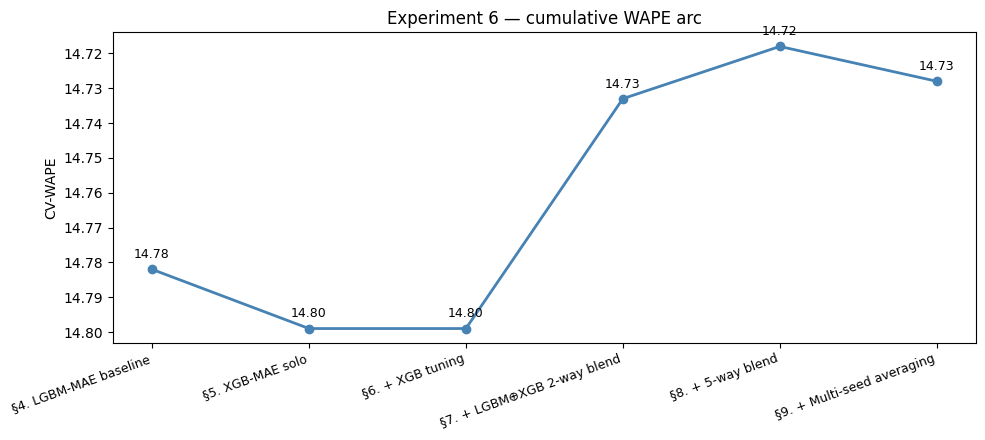

In [12]:
summary = pd.DataFrame([
    {"step": "§4. LGBM-MAE baseline",      "CV-WAPE": LGB_BASELINE_WAPE,
     "std": LGB_BASELINE_STD},
    {"step": "§5. XGB-MAE solo",            "CV-WAPE": XGB_SOLO_WAPE,
     "std": XGB_SOLO_STD},
    {"step": "§6. + XGB tuning",            "CV-WAPE": XGB_STEP1_WAPE,
     "std": float(np.std(xgb_solo_arr)) if XGB_STEP1_WAPE == XGB_SOLO_WAPE else np.nan},
    {"step": "§7. + LGBM⊕XGB 2-way blend",  "CV-WAPE": BLEND2_WAPE,
     "std": float(BLEND2_PER_FOLD.std())},
    {"step": "§8. + 5-way blend",           "CV-WAPE": BLEND5_WAPE,
     "std": float(BLEND5_PER_FOLD.std())},
    {"step": "§9. + Multi-seed averaging",  "CV-WAPE": FINAL_CV_WAPE,
     "std": np.nan},
]).round(3)
summary["Δ vs LGBM baseline"] = (LGB_BASELINE_WAPE - summary["CV-WAPE"]).round(3)
display(summary)

print()
print("Decisions applied to the final submission:")
print(f"  XGB hyperparameter tuning : {'✅' if XGB_STEP1_WAPE < XGB_SOLO_WAPE else '❌ (defaults kept)'}")
print(f"  LGBM⊕XGB 2-way blend       : {'✅' if APPLY_BLEND2 else '❌'}")
print(f"  5-way blend                : {'✅' if APPLY_BLEND5 else '❌'}")
print(f"  Multi-seed averaging        : {'✅' if APPLY_MULTISEED else '❌'}")
print()
print(f"Winning composition: {WINNER_KIND}")
print(f"Final CV-WAPE     : {FINAL_CV_WAPE:.3f}")
print(f"vs exp-5.1 CV-WAPE: 14.728  (Δ = {14.728 - FINAL_CV_WAPE:+.3f})")
print(f"Reference leaderboard for exp-5.1: 14.928 — expect this notebook to land within ±0.1 of that if no blend wins, or lower if §7/§8 won.")

# Plot the WAPE arc
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(len(summary)), summary["CV-WAPE"], marker="o", color="steelblue", linewidth=2)
for i, w in enumerate(summary["CV-WAPE"]):
    ax.annotate(f"{w:.2f}", (i, w), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)
ax.set_xticks(range(len(summary)))
ax.set_xticklabels(summary["step"], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("CV-WAPE")
ax.set_title("Experiment 6 — cumulative WAPE arc")
ax.invert_yaxis()
plt.tight_layout(); plt.show()